# 2.5D MMR modelling and inversion

Conductivity invariant along y, see [docs/mmr25.md](../docs/mmr25.md).

1. Forward modelling: Bz of a pole source next to a vertical dyke, measured off the line of the
   source, compared with the analytic solution of Edwards et al. (1978).
2. Inversion of synthetic Bx, By, Bz data for a conductive block.

The direct solver MUMPS is used if available (on macOS, mpi4py may need DYLD_LIBRARY_PATH to find the
MPI library), otherwise SuperLU.

In [1]:
import os
import sys

import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('..'))   # notebook run from the examples directory

from pymmr.finite_volume import calc_padding, has_mumps  # noqa: E402
from pymmr.mmr import GridMMR, VerticalDyke  # noqa: E402
from pymmr.inversion import Inversion, DataMMR  # noqa: E402

solver = 'mumps' if has_mumps else 'superlu'

## 1. Vertical dyke

A vertical dyke, 20 m wide and infinite in depth and along $y$, separates two half-spaces: 100 Ω·m on the
left, 10 Ω·m in the dyke ($0 \le x \le 20$ m), 300 Ω·m on the right.  A pole source at $x = -50$ m (return
electrode at infinity) injects 1 A.  $B_z$ is computed on three lines parallel to $x$, at $y$ = 10, 20 and 40 m,
and compared with the analytic solution of Edwards et al. (1978) (`pymmr.mmr.VerticalDyke`).

For a 2.5D grid, `GridMMR` takes two coordinate arrays, $(x, z)$.  The fields are computed for a set of
wavenumbers $k_y$ and transformed back to the $y$ domain, so sources and receivers can be anywhere in $y$.
The top cells are refined because the surface electrodes are placed at the centre of the first cell.

y =   10 m: max error 0.58% of max |Bz|
y =   20 m: max error 0.53% of max |Bz|
y =   40 m: max error 0.42% of max |Bz|


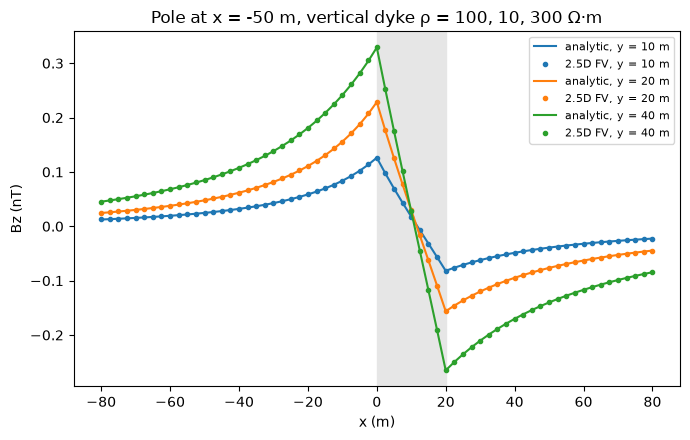

In [2]:
rho = (100.0, 10.0, 300.0)   # left, dyke, right (ohm m)
d = 20.0                     # dyke from x = 0 to x = d, infinite in depth and along y

# Grid: h = 5 m, top cells refined to 0.25 m (surface electrodes are placed at the first cell centre,
# see section 9 of docs/mmr25.md), padding on the sides and at the bottom.  The air layers are added
# by GridMMR.
h = 5.0
pad = np.cumsum(calc_padding(h, 15))
x = np.arange(-200.0, 200.0 + h / 2, h)
x = np.r_[x[0] - pad[::-1], x, x[-1] + pad]
z = np.arange(-150.0, h / 2, h)
zt = -np.cumsum(np.r_[np.full(4, 0.25), 0.25 * 1.5**np.arange(1, 20)])
zt = zt[zt > -3 * h]
z = np.unique(np.r_[z[z < zt[-1] - h / 2], zt[::-1], 0.0])
z = np.r_[z[0] - pad[::-1], z]

g = GridMMR((x, z), units='nT')     # 2 coordinate arrays: 2.5D model
g.set_solver(solver)

xc = 0.5 * (x[1:] + x[:-1])
rho_c = np.where(xc < 0.0, rho[0], np.where(xc <= d, rho[1], rho[2]))
sigma = np.tile(1.0 / rho_c, z.size - 1)          # x is the fast axis

# pole at x = -50 m, return electrode at infinity; receivers off the line of the source
xs = -50.0
yr = (10.0, 20.0, 40.0)
xo = np.array([[a, b, 0.0] for b in yr for a in np.arange(-80.0, 81.0, 2.5)])
g.set_survey_mmr(np.array([xs, 0.0, 0.0, np.inf, np.inf, np.inf]), xo, 1.0)
B = g.fwd_mod(sigma)
bz = VerticalDyke(*rho, d).fwd_mod(xo, xs)

fig, ax = plt.subplots(figsize=(7, 4.5))
for b in yr:
    i = xo[:, 1] == b
    line, = ax.plot(xo[i, 0], bz[i], label='analytic, y = {0:g} m'.format(b))
    ax.plot(xo[i, 0], B[i, 2], 'o', ms=3, color=line.get_color(), label='2.5D FV, y = {0:g} m'.format(b))
ax.axvspan(0.0, d, color='0.9')
ax.set_xlabel('x (m)')
ax.set_ylabel('Bz (nT)')
ax.set_title('Pole at x = {0:g} m, vertical dyke ρ = {1:g}, {2:g}, {3:g} Ω·m'.format(xs, *rho))
ax.legend(fontsize=8)
fig.tight_layout()

for b in yr:
    i = xo[:, 1] == b
    print('y = {0:4g} m: max error {1:.2%} of max |Bz|'.format(b, np.abs(B[i, 2] - bz[i]).max() / np.abs(bz[i]).max()))

## 2. Inversion of synthetic data

A conductive block, 0.1 S/m, 40 m wide, from 10 to 40 m depth, in a 0.01 S/m background, invariant along $y$.

- **Sources:** three current dipoles on the line $y = 0$, of different lengths and positions.
- **Receivers:** 11 stations from −50 to 50 m on the line ($y = 0$, where only $B_y$ is non-zero for a 2D model)
  and on two parallel lines at $y = \pm 20$ m.

The synthetic data (in pT) are inverted without noise, from a homogeneous starting and reference model.  The
inversion uses $\beta$ from 100 down to 1, and 4 iterations.  The true and recovered models are shown below.

misfit per iteration: [0.0804 0.0691 0.0582 0.047 ]


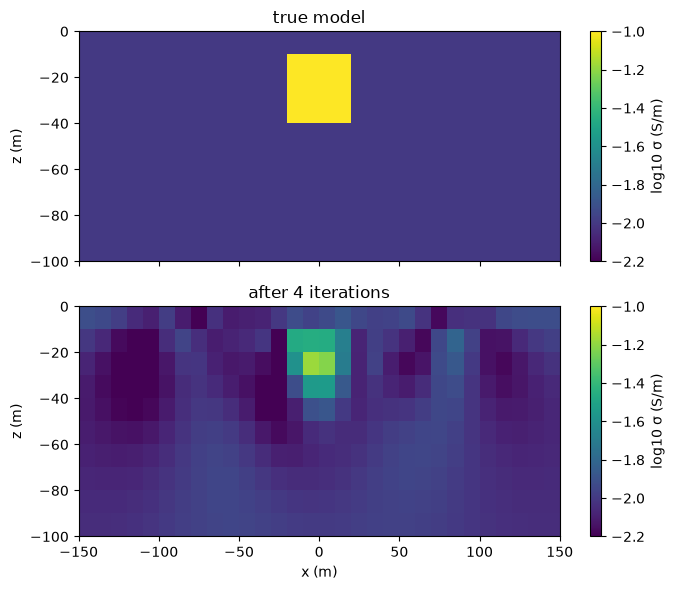

In [3]:
h = 10.0
pad = np.cumsum(calc_padding(h, 10))
x = np.arange(-150.0, 150.0 + h / 2, h)
x = np.r_[x[0] - pad[::-1], x, x[-1] + pad]
z = np.arange(-100.0, h / 2, h)
z = np.r_[z[0] - pad[::-1], z]
X, Z = np.meshgrid(0.5 * (x[1:] + x[:-1]), 0.5 * (z[1:] + z[:-1]))
s_true = 0.01 * np.ones(X.shape)
s_true[(np.abs(X) < 20) & (Z < -10) & (Z > -40)] = 0.1
s_true = s_true.ravel()

# 3 dipoles along the line, receivers on the line (By) and off the line (Bx, By, Bz)
dipoles = [[-100.0, 0, 0, 100, 0, 0], [-60.0, 0, 0, 80, 0, 0], [-80.0, 0, 0, 40, 0, 0]]
receivers = [[a, b, 0.0] for b in (0.0, 20.0, -20.0) for a in np.arange(-50.0, 51.0, 10.0)]
xs = np.array([c for c in dipoles for r in receivers])
xo = np.array([r for c in dipoles for r in receivers])

g = GridMMR((x, z))
g.set_solver(solver)
g.set_survey_mmr(xs, xo, 1.0)
data = g.fwd_mod(s_true)       # pT
data_mmr = DataMMR(xs=xs, xo=xo, data=data, wt=np.ones(3 * data.shape[0]), cs=np.ones(data.shape[0]),
                   date=None)

g = GridMMR((x, z))
g.set_solver(solver)
inv = Inversion()
inv.max_it = 4
inv.beta = 100.0
inv.beta_min = 1.0
inv.verbose = False
m0 = 0.01 * np.ones(g.dc.fv.nc)
S, data_inv, rms, misfit, smy = inv.run(g, m0=m0, m_ref=m0, data_mmr=data_mmr)
print('misfit per iteration:', np.round(misfit, 4))

fig, ax = plt.subplots(2, 1, figsize=(7, 6), sharex=True)
for a, s, title in ((ax[0], s_true, 'true model'), (ax[1], S[-1], 'after {0:d} iterations'.format(len(S)))):
    im = a.pcolormesh(x, z, np.log10(s.reshape(z.size - 1, x.size - 1)), vmin=-2.2, vmax=-1, cmap='viridis')
    a.set_xlim(-150, 150)
    a.set_ylim(-100, 0)
    a.set_ylabel('z (m)')
    a.set_title(title)
    fig.colorbar(im, ax=a, label='log10 σ (S/m)')
ax[1].set_xlabel('x (m)')
fig.tight_layout()

plt.show()